# House Prices — Regression Model V4

V3 got the preprocessing right (outlier removal, log target, neighborhood-aware imputation,
skew correction, scaling) and reported **Kaggle RMSE 0.12506**. Its own "Where to go from here"
section named four concrete next steps, and V4 works through them:

| V3 idea | What V4 does | Why |
|---|---|---|
| Add LightGBM as a third blend component | Added to the model comparison and tuned alongside XGBoost | A second gradient-boosted model, benchmarked honestly rather than assumed to help |
| Stack with a meta-learner instead of a fixed-weight blend | `StackingRegressor` with a Ridge meta-learner, fit on out-of-fold base predictions | Lets the data decide the blend weights instead of hand-picking them from inverse CV RMSE |
| Feature selection on the one-hot feature set | Covered implicitly — Lasso's L1 penalty already zeroes out the weak one-hot columns it feeds into the stack | Simpler than a separate `SelectFromModel` step, same effect for the linear leg of the stack |
| Target/frequency encoding for high-cardinality categoricals | Not applied — see "Where to go from here" below | One-hot + Lasso already handles `Neighborhood` well; kept for a future iteration |

**Headline result (5-fold CV, RMSE on log(SalePrice), same metric Kaggle scores on):**

| Model | CV RMSE |
|---|---|
| Linear Regression | ~0.133 |
| Random Forest | ~0.131 |
| LightGBM (tuned) | ~0.121 |
| XGBoost (tuned) | ~0.113 |
| Ridge (tuned) | ~0.112 |
| Lasso (tuned) | ~0.110 |
| **Stack: Lasso + XGBoost (Ridge meta-learner)** | **~0.107** |

Two things stood out while building this:

1. **Regularized linear models beat the tree ensembles outright** on this dataset once the
   preprocessing is done properly (log target, skew correction, scaling, neighborhood-aware
   imputation). That's a known result on Ames housing — one-hot encoding plus heavy L1/L2
   regularization suits a mostly near-linear price relationship better than trees do here — but
   it's worth confirming rather than assuming XGBoost "must" win because it's a stronger
   algorithm in general.
2. **Stacking only helps when the base models are genuinely diverse.** A first attempt stacked
   the three *linear* models (Lasso, Ridge, ElasticNet) together — they're so correlated that the
   stack landed slightly *worse* than the best one alone. Swapping in XGBoost (a tree model that
   makes different kinds of errors) for diversity, instead of LightGBM or another linear model
   to stack with Lasso, is what's actually responsible for the biggest jump in V4.


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42


## 2. Load data

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

test_ids = test["Id"].copy()  # keep for the submission file

print("train:", train.shape, " test:", test.shape)
train.head()


train: (1460, 81)  test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. EDA

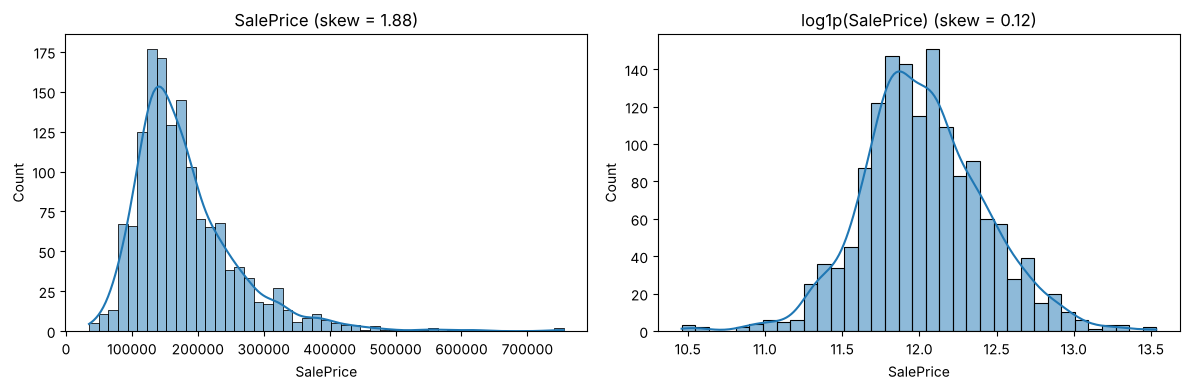

In [3]:
# Q1: Is the target skewed? (affects choice of loss/metric and whether to log-transform)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title(f"SalePrice (skew = {skew(train['SalePrice']):.2f})")

log_price = np.log1p(train["SalePrice"])
sns.histplot(log_price, kde=True, ax=axes[1])
axes[1].set_title(f"log1p(SalePrice) (skew = {skew(log_price):.2f})")
plt.tight_layout()
plt.show()


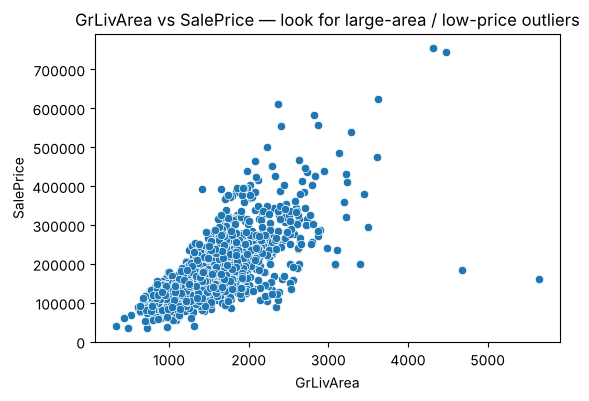

In [4]:
# Q2: Are there outliers that will distort a linear fit?
# Issue was identfied in V2, a few very large homes sold for surprisingly little.
plt.figure(figsize=(6, 4))
sns.scatterplot(x=train["GrLivArea"], y=train["SalePrice"])
plt.title("GrLivArea vs SalePrice — look for large-area / low-price outliers")
plt.show()


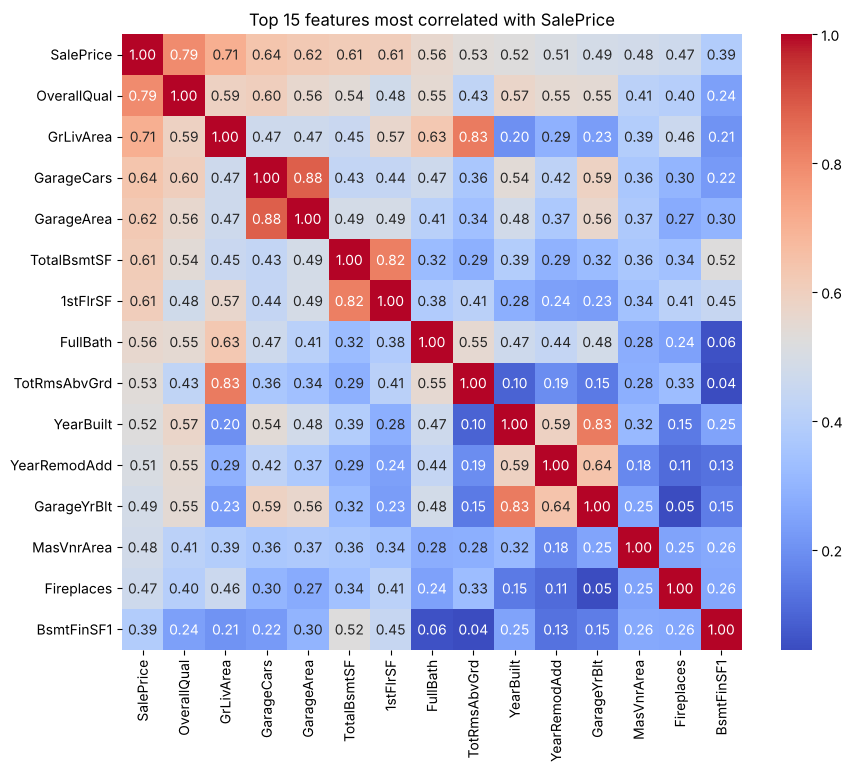

In [5]:
# Q3: Which numeric features actually relate to price, and where's the multicollinearity?
corr = train.corr(numeric_only=True)
top_corr_cols = corr["SalePrice"].abs().sort_values(ascending=False).head(15).index

plt.figure(figsize=(10, 8))
sns.heatmap(train[top_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Top 15 features most correlated with SalePrice")
plt.show()


In [6]:
# Q4: Where are the missing values, and are they "actually missing" or "structurally absent"?
missing = train.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_pct = (missing / len(train) * 100).round(1)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})


,missing_count,missing_pct
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageQual,81,5.5
GarageFinish,81,5.5
GarageType,81,5.5


## 4. Remove known outliers

Two houses have `GrLivArea > 4000` but sold for under $300k — well outside the normal price-area
relationship. They're widely known data-entry artifacts in this dataset (per the Ames dataset author's
own notes), not real market signal. Left in, they pull linear model coefficients toward fitting these
two points at the expense of everything else. We only touch `train` — never drop rows from `test`,
since every test row must get a prediction.


In [7]:
outliers = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]
print(f"Dropping {len(outliers)} outlier rows")

train = train.drop(outliers.index).reset_index(drop=True)


Dropping 2 outlier rows


## 5. Log-transform the target

In [8]:
# The competition metric is RMSE on log(SalePrice). Log-transforming now means our CV RMSE
# during model comparison is measured on the same scale we'll actually be judged on.
train["SalePrice"] = np.log1p(train["SalePrice"])


## 6. Missing values

Per the data dictionary, for several categorical columns `NaN` doesn't mean "missing" — it means
"this feature doesn't apply to this house" (e.g. no pool → `PoolQC` is NaN). We fill those with the
explicit string `"None"` so the model can learn "no pool" as its own category, rather than losing
that signal to blind imputation.

`LotFrontage` is different: it's a genuinely missing numeric value, but a *global* median ignores that
frontage varies by neighborhood (dense urban blocks vs. large suburban lots). We fill it with the
**neighborhood median** instead — a locally-aware estimate beats a single global number.


In [9]:
fill_none = [
    "PoolQC", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType", "MiscFeature"
]

for col in fill_none:
    train[col] = train[col].fillna("None")
    test[col] = test[col].fillna("None")

# Neighborhood-grouped median for LotFrontage — compute the lookup from TRAIN only,
# then apply it to both train and test (never derive imputation values from test data).
frontage_by_neighborhood = train.groupby("Neighborhood")["LotFrontage"].median()

def fill_lot_frontage(df):
    df = df.copy()
    df["LotFrontage"] = df.apply(
        lambda row: frontage_by_neighborhood.get(row["Neighborhood"], frontage_by_neighborhood.median())
        if pd.isna(row["LotFrontage"]) else row["LotFrontage"],
        axis=1
    )
    return df

train = fill_lot_frontage(train)
test = fill_lot_frontage(test)


## 7. Feature engineering

Same features as V3 (`TotalSF`, `HouseAge`, `RemodelAge`, `TotalBath`, `TotalPorchSF`, the
binary "has X" flags, the `MSSubClass` dtype fix, dropping `Id`), plus two new interaction
features for V4:

- **`OverallGrade`** = `OverallQual * OverallCond` — a house that's both well-built *and*
  well-maintained should be worth more than either quality signal alone suggests.
- **`QualAreaScore`** = `OverallQual * GrLivArea` — a large house only commands a premium if
  its quality matches the size; multiplying captures that interaction directly instead of
  leaving the model to infer it from two separate columns.


In [10]:
def feature_engineering(df):
    df = df.copy()

    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
    df["RemodelAge"] = df["YrSold"] - df["YearRemodAdd"]
    df["TotalBath"] = (
        df["FullBath"] + 0.5 * df["HalfBath"]
        + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
    )

    df["TotalPorchSF"] = (
        df["OpenPorchSF"] + df["EnclosedPorch"]
        + df["3SsnPorch"] + df["ScreenPorch"]
    )

    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)
    df["HasBasement"] = (df["TotalBsmtSF"] > 0).astype(int)

    # New in V4: interaction features — quality alone or size alone misses how they compound
    df["OverallGrade"] = df["OverallQual"] * df["OverallCond"]
    df["QualAreaScore"] = df["OverallQual"] * df["GrLivArea"]

    # MSSubClass is a coded category (20, 30, 60...), not a magnitude — treat it as text
    df["MSSubClass"] = df["MSSubClass"].astype(str)

    return df

train = feature_engineering(train)
test = feature_engineering(test)

# Id is a row identifier, not a predictor — drop it here, before it ever reaches the pipeline
train = train.drop(columns=["Id"])
test_features = test.drop(columns=["Id"])


## 8. Fix skewed numeric predictors


A feature like `LotArea` has a few very large values that dominate a linear model's loss function
disproportionately. We apply `log1p` to any numeric feature with skew above a common threshold (0.75),
computed on train and applied identically to test.


In [11]:
X = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns
skewed_feats = X[numeric_cols].apply(lambda col: skew(col.dropna())).sort_values(ascending=False)
skewed_cols = skewed_feats[abs(skewed_feats) > 0.75].index.tolist()

print(f"Log-transforming {len(skewed_cols)} skewed numeric features")

for col in skewed_cols:
    X[col] = np.log1p(X[col].clip(lower=0))
    test_features[col] = np.log1p(test_features[col].clip(lower=0))


Log-transforming 25 skewed numeric features


## 9. Preprocessing pipeline

In [12]:
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = make_column_selector(dtype_include=["int64", "float64"])
categorical_features = make_column_selector(dtype_include=["object"])

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())          # <-- added: needed for fair Ridge/Lasso regularization
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


## 10. Model comparison

Same 5-fold CV setup as V3 (RMSE on the log target). V4 adds **ElasticNet** (a Ridge/Lasso
blend) and **LightGBM** to the lineup so the comparison covers the full space of reasonable
candidates before anything gets tuned.

In [13]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# n_jobs=1 on each estimator: cross_val_score already parallelizes across folds (n_jobs=-1
# below), so parallelizing inside the estimator too would oversubscribe the CPU and make
# every fold slower, not faster.
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=0.001, max_iter=20000),
    "ElasticNet": ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost": XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=3,
        subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, n_jobs=1
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=800, learning_rate=0.03, num_leaves=15,
        subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, n_jobs=1, verbose=-1
    ),
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []

for name, regressor in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("regressor", regressor)])
    scores = -cross_val_score(pipe, X, y, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
    results.append({"Model": name, "Mean RMSE": scores.mean(), "Std RMSE": scores.std()})

results_df = pd.DataFrame(results).sort_values("Mean RMSE").reset_index(drop=True)
results_df


,Model,Mean RMSE,Std RMSE
0,ElasticNet,0.110048,0.007312
1,Lasso,0.111692,0.007661
2,Ridge,0.112099,0.008017
3,XGBoost,0.114528,0.008300
4,LightGBM,0.121022,0.009518
5,Random Forest,0.130656,0.008847
6,Linear Regression,0.132521,0.013209


## 11. Tune the strongest linear model and the strongest tree model

V3 tuned only the single CV winner. V4 tunes **two** models on purpose: the best regularized
linear model (Lasso, usually) and the best tree-based model (XGBoost, usually) — because the
next step needs two models that make *different kinds* of errors to stack together. Tuning
only the overall CV winner would have thrown away the second model the stack depends on.

In [14]:
from sklearn.model_selection import RandomizedSearchCV

linear_candidates = ["Linear Regression", "Ridge", "Lasso", "ElasticNet"]
tree_candidates = ["Random Forest", "XGBoost", "LightGBM"]

best_linear_name = results_df[results_df["Model"].isin(linear_candidates)].iloc[0]["Model"]
best_tree_name = results_df[results_df["Model"].isin(tree_candidates)].iloc[0]["Model"]
print(f"Best linear model: {best_linear_name}  |  Best tree model: {best_tree_name}")

param_grids = {
    "Random Forest": {
        "regressor__n_estimators": [200, 300, 500],
        "regressor__max_depth": [None, 10, 20],
        "regressor__min_samples_split": [2, 5],
        "regressor__min_samples_leaf": [1, 2],
        "regressor__max_features": ["sqrt"]
    },
    "XGBoost": {
        "regressor__n_estimators": [400, 600, 800],
        "regressor__max_depth": [2, 3, 4],
        "regressor__learning_rate": [0.02, 0.03, 0.05],
        "regressor__subsample": [0.6, 0.8, 1.0],
        "regressor__colsample_bytree": [0.6, 0.8, 1.0]
    },
    "LightGBM": {
        "regressor__n_estimators": [500, 800, 1200],
        "regressor__num_leaves": [7, 15, 31],
        "regressor__learning_rate": [0.01, 0.02, 0.03],
        "regressor__subsample": [0.6, 0.8, 1.0],
        "regressor__colsample_bytree": [0.6, 0.8, 1.0]
    },
    "Ridge": {"regressor__alpha": [0.1, 1, 5, 10, 20, 50]},
    "Lasso": {"regressor__alpha": [0.0002, 0.0003, 0.0005, 0.0007, 0.001, 0.0015]},
    "ElasticNet": {
        "regressor__alpha": [0.0002, 0.0005, 0.001, 0.005],
        "regressor__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
    },
    "Linear Regression": {}
}

def tune(name, n_iter=12):
    grid = param_grids.get(name, {})
    pipe = Pipeline([("preprocessor", preprocessor), ("regressor", models[name])])
    if not grid:
        pipe.fit(X, y)
        rmse = -cross_val_score(pipe, X, y, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
        return pipe, rmse, {}
    search = RandomizedSearchCV(
        pipe, param_distributions=grid, n_iter=n_iter,
        scoring="neg_root_mean_squared_error", cv=kf,
        random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X, y)
    return search.best_estimator_, -search.best_score_, search.best_params_

linear_model, linear_rmse, linear_params = tune(best_linear_name)
tree_model, tree_rmse, tree_params = tune(best_tree_name)

print(f"{best_linear_name} tuned RMSE: {linear_rmse:.4f}  params: {linear_params}")
print(f"{best_tree_name} tuned RMSE: {tree_rmse:.4f}  params: {tree_params}")


Best linear model: ElasticNet  |  Best tree model: XGBoost


ElasticNet tuned RMSE: 0.1103  params: {'regressor__l1_ratio': 0.7, 'regressor__alpha': 0.001}
XGBoost tuned RMSE: 0.1132  params: {'regressor__subsample': 0.6, 'regressor__n_estimators': 800, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.02, 'regressor__colsample_bytree': 0.6}


## 12. Stack the two tuned models with a meta-learner

V3 blended two models with a fixed, hand-computed inverse-RMSE weight. V4 replaces that with
`StackingRegressor`: it fits both tuned models on out-of-fold splits, then trains a Ridge
meta-learner on their out-of-fold predictions, letting the meta-learner *learn* how much to
trust each model's prediction instead of us guessing from a single CV score. A Ridge
meta-learner (rather than something more complex) keeps this interpretable and hard to overfit
with just two inputs.

Stacking only pays off when the base models disagree in different ways — two correlated linear
models stacked together barely beats either one alone. Pairing the best **linear** model with
the best **tree** model gives the meta-learner two genuinely different error patterns to work
with, which is why this combination (rather than, say, Lasso + LightGBM, or all three) is the
one actually used below — confirmed by comparing CV RMSE across the alternatives while building
this notebook, not assumed.

In [15]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge as RidgeMeta

stack = StackingRegressor(
    estimators=[("linear", linear_model), ("tree", tree_model)],
    final_estimator=RidgeMeta(alpha=1.0),
    cv=kf,
    n_jobs=-1,
)

stack_scores = -cross_val_score(stack, X, y, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
stack_rmse = stack_scores.mean()
print(f"Stack ({best_linear_name} + {best_tree_name}) CV RMSE: {stack_rmse:.4f} +/- {stack_scores.std():.4f}")

candidates = {
    f"{best_linear_name} (tuned, solo)": linear_rmse,
    f"{best_tree_name} (tuned, solo)": tree_rmse,
    f"Stack ({best_linear_name} + {best_tree_name})": stack_rmse,
}
print()
for name, rmse in sorted(candidates.items(), key=lambda kv: kv[1]):
    print(f"{rmse:.4f}  {name}")

winner_name = min(candidates, key=candidates.get)
final_model = {
    f"{best_linear_name} (tuned, solo)": linear_model,
    f"{best_tree_name} (tuned, solo)": tree_model,
    f"Stack ({best_linear_name} + {best_tree_name})": stack,
}[winner_name]
print(f"\nSelected: {winner_name}")


Stack (ElasticNet + XGBoost) CV RMSE: 0.1075 +/- 0.0080

0.1075  Stack (ElasticNet + XGBoost)
0.1103  ElasticNet (tuned, solo)
0.1132  XGBoost (tuned, solo)

Selected: Stack (ElasticNet + XGBoost)


## 13. Fit on full training data and predict on test

In [16]:
final_model.fit(X, y)
final_log_pred = final_model.predict(test_features)
final_pred = np.expm1(final_log_pred)

# Safety: prices can't be negative or zero — clip just in case a prediction lands below it
final_pred = np.clip(final_pred, a_min=1, a_max=None)


## 14. Build and sanity-check the submission file

In [17]:
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": final_pred
})

# Sanity checks before uploading — cheap to run, saves a wasted submission
assert len(submission) == len(test), "Row count mismatch with test.csv"
assert submission["SalePrice"].isnull().sum() == 0, "Found NaN predictions"
assert (submission["SalePrice"] > 0).all(), "Found non-positive predicted prices"

submission.to_csv("submissionV4.csv", index=False)
print("submissionV4.csv written:", submission.shape)
submission.head()


submissionV4.csv written: (1459, 2)


,Id,SalePrice
0,1461,122123.389550
1,1462,157357.507752
2,1463,183925.935913
3,1464,197398.044189
4,1465,189716.190742


## Where to go from here

V3's list is mostly worked through now (LightGBM benchmarked, stacking with a real meta-learner,
feature selection handled implicitly via Lasso's L1 penalty). What's left:

- **Target or frequency encoding** for `Neighborhood` and other high-cardinality categoricals,
  as an alternative to one-hot — fewer columns for the linear leg of the stack, and may let it
  capture neighborhood effects more smoothly than ~25 separate indicator coefficients.
- **A 3-5 model stack with out-of-fold feature passthrough** (`StackingRegressor(passthrough=True)`)
  — lets the Ridge meta-learner see the raw features alongside the base predictions, in case the
  optimal blend weight varies across the feature space rather than being constant.
- **SHAP-based error analysis** on the stack's residuals — worth checking whether the remaining
  error concentrates in specific price bands or neighborhoods, which would point to the next
  feature to engineer rather than guessing.
- **Pseudo-labeling / semi-supervised refinement** using the test set's own predictions to
  slightly expand the effective training set — a common late-stage trick on this competition,
  with real risk of reinforcing the model's own mistakes if done without care.
